# Industry Project: Shipping a PyTorch Model: Export, Fast Inference and Quantization (Production-Style)

> **Who is this notebook for?** Someone who can train a model in PyTorch (for example with `16_industry_pytorch_training_pipeline.ipynb`) and now asks: *"How do I actually put this into a product?"*
> No prior knowledge of ONNX, TorchScript or quantization is needed. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from `08_model_compression` and `13_quantization_and_compression_advanced`

| `08_model_compression`, `13_quantization_...` | This notebook |
|---|---|
| Explain **how** quantization, pruning and distillation work (math, formats, papers) | **Measures** what export and quantization do for *your* model: size, speed, accuracy |
| Focus on huge models (LLMs, GPTQ, AWQ) | A small model you can export, benchmark and serve on a laptop CPU in minutes |
| Stop at the compressed model | Goes on to **parity tests**, **latency percentiles**, a **validated inference service** and a release **checklist** |

---

### The business problem

The digit-reading model from notebook 16 (scanned forms → digits) worked in a notebook. Now two teams want to use it:

1. **The forms API team** runs a Python microservice on cheap CPU machines. A form has about **20 digits**, and the service-level objective (SLO) is **p95 latency below 10 ms per form**. Each container has a small memory budget.
2. **The scanner-app team** builds a desktop application in **C# / Java** and cannot ship Python at all.

**Your job:** turn the trained PyTorch model into deployable artifacts, prove they give the **same answers** as the original, measure **speed and size**, decide whether **int8 quantization** is worth it (budget: lose at most **0.5 accuracy points**), and wrap everything in a small, safe **inference service**.

### Deployment options at a glance

| Format | What it is | Who uses it |
|---|---|---|
| **PyTorch eager** (`state_dict` + Python class) | the normal model; needs your Python code | research, Python services, quick prototypes |
| **TorchScript** (`torch.jit`) | the model saved *with* its computation graph; loads without your class, also from C++ (LibTorch) | many existing production systems (now in maintenance mode, see below) |
| **`torch.export`** (`.pt2`) | the modern PyTorch graph format; the base for the new ONNX exporter, `torch.compile`, ExecuTorch (mobile) | new PyTorch deployments |
| **ONNX** + **ONNX Runtime** | an open, framework-neutral model format and a fast inference engine with APIs for Python, C#, Java, C++, JavaScript | cross-language and cross-hardware deployment, Azure/Windows, edge devices |

### Table of Contents
1. Setup: imports and config
2. Train a small model quickly
3. Inference basics: `model.eval()` and `torch.inference_mode()`
4. Package preprocessing inside the model
5. TorchScript (and a word on `torch.export`)
6. Export to ONNX with a dynamic batch size
7. Run with ONNX Runtime and check numerical parity
8. Benchmarking latency and throughput properly
9. Dynamic quantization: accuracy vs speed vs size
10. A small inference service with input validation and batching
11. Automated release tests
12. Production checklist, summary and resources

---
## 1. Setup: imports and config

All the numbers that matter for the release (SLO, accuracy budget, benchmark settings) live in one config object.

**Threads matter for benchmarks.** We pin PyTorch and ONNX Runtime to **one thread**. This is common in production too: a CPU server usually runs several worker processes (one per core) and each worker uses one thread, which gives the most predictable latency. It also makes the comparison fair, since every engine gets the same hardware.

In [1]:
# ---- Standard library ----
import copy                         # copies of models (quantization must not modify the original)
import hashlib                      # file checksums (integrity check of the deployed artifact)
import json                         # metadata files
import logging                      # status messages
import tempfile                     # temporary folder for artifacts (keeps the repo clean)
import time                         # timing
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import onnx                         # the ONNX file format (load, check, inspect)
import onnxruntime as ort           # the inference engine
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")   # e.g. deprecation notices of torch.jit / torch.ao.quantization
# Root logger at WARNING hides the chatty INFO logs of the exporter/quantizer; our own logger shows INFO
logging.basicConfig(level=logging.WARNING, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("serve")
log.setLevel(logging.INFO)


@dataclass(frozen=True)
class ServeConfig:
    seed: int = 42
    hidden_size: int = 1024              # width of the MLP's hidden layers (~1.1M parameters)
    epochs: int = 30                     # quick training (the full pipeline is in notebook 16)
    lr: float = 1e-3
    num_threads: int = 1                 # one thread per worker process
    form_size: int = 20                  # digits per scanned form = typical request batch
    latency_slo_ms: float = 10.0         # p95 latency target for one form
    max_accuracy_drop: float = 0.005     # quantization may cost at most 0.5 accuracy points
    max_batch_size: int = 256            # the service splits bigger requests into chunks
    n_warmup: int = 20                   # benchmark: calls ignored before timing starts
    n_iter: int = 200                    # benchmark: timed calls per measurement


CFG = ServeConfig()
torch.manual_seed(CFG.seed)
np.random.seed(CFG.seed)
torch.set_num_threads(CFG.num_threads)

ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="digit_reader_"))   # in real life: models/digit_reader/v1/
log.info("torch %s | onnx %s | onnxruntime %s", torch.__version__, onnx.__version__, ort.__version__)
log.info("Artifacts will be written to %s", ARTIFACT_DIR)

2026-10-21 16:40:25,654 | INFO | torch 2.12.1+cpu | onnx 1.23.2 | onnxruntime 1.27.0


2026-10-21 16:40:25,655 | INFO | Artifacts will be written to /tmp/digit_reader_r03pwld2


---
## 2. Train a small model quickly

The professional training pipeline (sanity checks, early stopping, checkpoints...) is the topic of notebook 16. Here we only need *a* trained model, so we use a short, compact loop.

We deliberately use an **MLP** (only `Linear` layers) with about 1.1 million parameters: `Linear` layers are what dynamic quantization accelerates (Section 9), and they are also the bulk of Transformers and recommendation models in industry.

In [2]:
digits = load_digits()
images = digits.images.astype(np.float32)         # raw scans, shape (n, 8, 8), values 0..16
labels = digits.target.astype(np.int64)
X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2,
                                                    stratify=labels, random_state=CFG.seed)
NORM_MEAN, NORM_STD = float(X_train.mean()), float(X_train.std())   # fitted on TRAIN only
print(f"train={len(X_train)} test={len(X_test)} | normalisation mean={NORM_MEAN:.3f} std={NORM_STD:.3f}")


class DigitMLP(nn.Module):
    """Expects NORMALISED images of shape [batch, 8, 8]; returns logits [batch, 10]."""

    def __init__(self, hidden: int = 1024, dropout: float = 0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                          # [batch, 8, 8] -> [batch, 64]
            nn.Linear(64, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def normalise(x: np.ndarray) -> torch.Tensor:
    return torch.from_numpy((x - NORM_MEAN) / NORM_STD)


model = DigitMLP(CFG.hidden_size)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=1e-2)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(normalise(X_train), torch.from_numpy(y_train)),
                                     batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(CFG.seed))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs * len(loader))

t0 = time.perf_counter()
for epoch in range(CFG.epochs):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

model.eval()
with torch.inference_mode():
    fp32_test_acc = (model(normalise(X_test)).argmax(1).numpy() == y_test).mean()
print(f"Trained in {time.perf_counter() - t0:.1f}s | parameters: {sum(p.numel() for p in model.parameters()):,} "
      f"| test accuracy: {fp32_test_acc:.4f}")

train=1437 test=360 | normalisation mean=4.895 std=6.021


Trained in 37.9s | parameters: 1,126,410 | test accuracy: 0.9861


---
## 3. Inference basics: `model.eval()` and `torch.inference_mode()`

Two lines that every inference code path must have, and that beginners forget all the time:

1. **`model.eval()`** switches layers that behave differently during training: **Dropout** is turned off and **BatchNorm** uses its stored running statistics. Without it, the *same* input gives *different*, worse predictions on every call.
2. **`torch.inference_mode()`** (or the older `torch.no_grad()`) tells PyTorch not to record operations for back-propagation. That saves memory and time. `inference_mode` is the stricter, slightly faster version and is recommended for pure inference.

In [3]:
x_one_form = normalise(X_test[:CFG.form_size])            # one form = 20 digits

model.train()                                               # the bug: forgot eval()
with torch.inference_mode():
    a, b = model(x_one_form), model(x_one_form)
print(f"train mode: two calls on the same input differ by up to {(a - b).abs().max():.3f} (dropout is active)")

model.eval()                                                # the fix
with torch.inference_mode():
    a, b = model(x_one_form), model(x_one_form)
print(f"eval mode : two calls differ by {(a - b).abs().max():.1f}")

# Gradient tracking: outputs computed normally remember how they were computed (costs memory)
print("requires_grad without inference_mode:", model(x_one_form).requires_grad)
with torch.inference_mode():
    print("requires_grad with inference_mode   :", model(x_one_form).requires_grad)

train mode: two calls on the same input differ by up to 3.456 (dropout is active)
eval mode : two calls differ by 0.0
requires_grad without inference_mode: True
requires_grad with inference_mode   : False


---
## 4. Package preprocessing inside the model

A classic production bug is **training/serving skew**: the training code normalised pixels with `(x - 4.9) / 6.0`, but the service written by another team forgets it, or uses different numbers. The model still returns confident predictions, just wrong ones, and nobody notices.

The fix: put the preprocessing **inside the exported model**. Our `DigitReader` takes **raw pixels (0..16)** exactly as the scanner delivers them, normalises them with constants stored as **buffers** (saved with the weights), runs the network and returns **probabilities**. Now the exported file is self-contained: no team can forget a step.

In [4]:
class DigitReader(nn.Module):
    """Raw scans [batch, 8, 8] with values 0..16 -> class probabilities [batch, 10]."""

    def __init__(self, net: nn.Module, mean: float, std: float):
        super().__init__()
        self.net = net
        # register_buffer = a tensor that is saved/exported with the model but is not trained
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32))

    def forward(self, pixels: torch.Tensor) -> torch.Tensor:
        logits = self.net((pixels - self.mean) / self.std)
        return F.softmax(logits, dim=-1)


reader = DigitReader(model, NORM_MEAN, NORM_STD).eval()
raw_form = torch.from_numpy(X_test[:CFG.form_size])        # raw pixels, no manual normalisation

with torch.inference_mode():
    reference = F.softmax(model(normalise(X_test[:CFG.form_size])), dim=-1)
    packaged = reader(raw_form)
print(f"Max difference packaged vs manual preprocessing: {(reference - packaged).abs().max():.2e}")

Max difference packaged vs manual preprocessing: 0.00e+00


---
## 5. TorchScript (and a word on `torch.export`)

**TorchScript** records the model's computation as a graph and saves it with the weights. The saved file can be loaded **without the Python class** (`torch.jit.load`), even from C++ via LibTorch.

- `torch.jit.trace` runs the model once on an example input and records the operations. Simple and robust for models without data-dependent `if`/`for` logic (like ours).
- `torch.jit.script` compiles the Python code itself and also keeps control flow.

> ⚠️ **Status in 2025/2026:** TorchScript is in *maintenance mode*. PyTorch recommends **`torch.export`** for new projects (it is what the new ONNX exporter, `torch.compile` and ExecuTorch for mobile build on). You will still meet TorchScript in many existing systems, so it is worth knowing. We show both.

In [5]:
TS_PATH = ARTIFACT_DIR / "digit_reader.torchscript.pt"
traced = torch.jit.trace(reader, raw_form)                  # record the graph on an example input
traced.save(str(TS_PATH))

loaded_ts = torch.jit.load(str(TS_PATH))                    # note: no DigitReader class needed here
with torch.inference_mode():
    ts_out = loaded_ts(torch.from_numpy(X_test[:7]))        # a different batch size than the example
    eager_out = reader(torch.from_numpy(X_test[:7]))
print(f"TorchScript file: {TS_PATH.stat().st_size / 1e6:.2f} MB | "
      f"max diff vs eager: {(ts_out - eager_out).abs().max():.2e}")

# The modern alternative: torch.export produces an ExportedProgram (.pt2)
batch = torch.export.Dim("batch", min=1, max=4096)           # the batch dimension may vary
exported = torch.export.export(reader, (raw_form,), dynamic_shapes={"pixels": {0: batch}})
PT2_PATH = ARTIFACT_DIR / "digit_reader.pt2"
torch.export.save(exported, PT2_PATH)
with torch.inference_mode():
    pt2_out = torch.export.load(PT2_PATH).module()(torch.from_numpy(X_test[:7]))
print(f"torch.export file: {PT2_PATH.stat().st_size / 1e6:.2f} MB | max diff vs eager: {(pt2_out - eager_out).abs().max():.2e}")

TorchScript file: 4.53 MB | max diff vs eager: 0.00e+00


torch.export file: 4.54 MB | max diff vs eager: 0.00e+00


---
## 6. Export to ONNX with a dynamic batch size

**ONNX** (Open Neural Network Exchange) is an open file format for models. Once exported, the model can run in **ONNX Runtime** from Python, C#, Java, C++ or JavaScript, on CPUs, GPUs and many accelerators, without PyTorch installed. That is exactly what the scanner-app team needs.

Important export settings:
- **Example input**: the exporter traces the model with it (any valid shape works).
- **`dynamic_shapes`**: without it, the batch size of the example (20) is *baked into* the file and a request with 7 digits would fail. We mark dimension 0 as dynamic.
- **`input_names` / `output_names`**: readable names (`pixels`, `probabilities`) form the "API contract" of the file.
- Since PyTorch 2.9 `torch.onnx.export` uses the new **`torch.export`-based exporter** by default (`dynamo=True`; it needs the `onnxscript` package). `external_data=False` keeps the weights inside one `.onnx` file (models > 2 GB must use external data).

After exporting we run **`onnx.checker`**, which validates that the file is a well-formed ONNX model, and look at the graph.

In [6]:
ONNX_PATH = ARTIFACT_DIR / "digit_reader.onnx"
t0 = time.perf_counter()
onnx_program = torch.onnx.export(
    reader, (raw_form,), str(ONNX_PATH),
    input_names=["pixels"], output_names=["probabilities"],
    dynamic_shapes={"pixels": {0: torch.export.Dim("batch")}},   # dimension 0 (batch) may vary
    external_data=False,                                          # one self-contained file
    verbose=False,
)
log.info("ONNX export took %.1fs", time.perf_counter() - t0)

onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)                               # raises if the file is malformed


def describe(value_info) -> str:
    dims = [d.dim_param or d.dim_value for d in value_info.type.tensor_type.shape.dim]
    return f"{value_info.name} {dims}"


print("ONNX opset   :", onnx_model.opset_import[0].version)
print("Inputs       :", [describe(i) for i in onnx_model.graph.input])
print("Outputs      :", [describe(o) for o in onnx_model.graph.output])
print("Operators    :", [node.op_type for node in onnx_model.graph.node])
print(f"File size    : {ONNX_PATH.stat().st_size / 1e6:.2f} MB")

2026-10-21 16:41:21,710 | INFO | ONNX export took 9.2s


ONNX opset   : 20
Inputs       : ["pixels ['batch', 8, 8]"]
Outputs      : ["probabilities ['batch', 10]"]
Operators    : ['Shape', 'Sub', 'Div', 'Concat', 'Reshape', 'Gemm', 'Relu', 'Gemm', 'Relu', 'Gemm', 'Softmax']
File size    : 4.52 MB


The graph is small and readable: the normalisation (`Sub`, `Div`) is part of the model, followed by matrix multiplications (`Gemm`), `Relu` and the final `Softmax`. Dropout has disappeared because we exported in eval mode. The input dimension is called `batch` instead of a fixed number, so any batch size is accepted.

---
## 7. Run with ONNX Runtime and check numerical parity

An `InferenceSession` loads the model **once** (it optimises the graph at load time) and can then be called many times.

**Parity check:** different engines use different math kernels, so outputs will not be *bit*-identical, but they must agree to within normal float32 rounding noise (around `1e-6`). We check three things:
1. the largest absolute difference of the probabilities,
2. `np.testing.assert_allclose` with explicit tolerances (this is what a CI test would do),
3. that the **predicted class is identical** for every test image (what users actually see).

We also call the session with several batch sizes to prove that the dynamic batch dimension works.

In [7]:
def make_session(path: Path, threads: int = CFG.num_threads) -> ort.InferenceSession:
    options = ort.SessionOptions()
    options.intra_op_num_threads = threads                    # threads inside one operator
    options.inter_op_num_threads = 1                          # threads across independent operators
    options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL   # fuse ops, fold constants
    # On a GPU machine you would list ["CUDAExecutionProvider", "CPUExecutionProvider"] (needs onnxruntime-gpu)
    return ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


session = make_session(ONNX_PATH)
print("Providers:", session.get_providers())

with torch.inference_mode():
    torch_probs = reader(torch.from_numpy(X_test)).numpy()                # all 360 test images
onnx_probs = session.run(["probabilities"], {"pixels": X_test})[0]       # numpy in, numpy out

print(f"1. max |PyTorch - ONNX| = {np.abs(torch_probs - onnx_probs).max():.2e}")
np.testing.assert_allclose(onnx_probs, torch_probs, rtol=1e-4, atol=1e-5)
print("2. assert_allclose(rtol=1e-4, atol=1e-5): PASSED")
same_class = (torch_probs.argmax(1) == onnx_probs.argmax(1)).mean()
print(f"3. identical predicted class on {same_class:.1%} of test images")

for batch_size in [1, 7, CFG.form_size, len(X_test)]:
    out = session.run(None, {"pixels": X_test[:batch_size]})[0]
    print(f"   batch size {batch_size:3d} -> output shape {out.shape}")

Providers: ['CPUExecutionProvider']


1. max |PyTorch - ONNX| = 2.38e-07
2. assert_allclose(rtol=1e-4, atol=1e-5): PASSED
3. identical predicted class on 100.0% of test images
   batch size   1 -> output shape (1, 10)
   batch size   7 -> output shape (7, 10)
   batch size  20 -> output shape (20, 10)


   batch size 360 -> output shape (360, 10)


---
## 8. Benchmarking latency and throughput properly

"It feels fast" is not a measurement. Industry benchmarks follow a few rules:

- **Warm-up first.** The first calls are slow (memory allocation, lazy initialisation, CPU caches). We discard `n_warmup` calls.
- **Many repetitions + percentiles.** Users experience the *distribution* of latencies. We report the median (**p50**, the typical request) and **p95** (1 in 20 requests is slower than this); SLOs are almost always written on p95/p99, not on the average.
- **`time.perf_counter()`**, the high-resolution clock (on a GPU you would also need `torch.cuda.synchronize()`, because GPU calls return before the work is done).
- **Same inputs, same threads** for every engine; report the hardware.
- **Interleave the candidates.** Background activity (other processes, CPU frequency changes) comes and goes. If engine A is measured first and engine B a minute later, B may look slower just because the machine got busier. Our `benchmark` runs all engines in alternating **rounds**, so noise hits all of them equally.
- **Latency vs throughput.** *Latency* = time for one request. *Throughput* = items per second. Bigger batches usually increase throughput (the fixed overhead per call is shared) but each request waits longer.

> ⚠️ This notebook ran on a **shared machine** with other jobs, so absolute numbers are noisy (especially p95). Trust the *relative* comparisons, and always re-run benchmarks on the real production hardware.

In [8]:
def benchmark(runners: dict, x, n_warmup: int = CFG.n_warmup, n_iter: int = CFG.n_iter,
              rounds: int = 5) -> pd.DataFrame:
    """Time every runner on input x. Returns latency percentiles (ms) and throughput (items/s).

    Runners are measured in interleaved rounds (A, B, C, A, B, C, ...) so that background
    noise on the machine affects all of them equally."""
    for fn in runners.values():                      # warm-up calls are not measured
        for _ in range(n_warmup):
            fn(x)
    times_ms = {name: [] for name in runners}
    for _ in range(rounds):
        for name, fn in runners.items():
            for _ in range(n_iter // rounds):
                start = time.perf_counter()
                fn(x)
                times_ms[name].append((time.perf_counter() - start) * 1000)
    return pd.DataFrame([{"engine": name, "p50_ms": np.percentile(t, 50), "p95_ms": np.percentile(t, 95),
                          "p99_ms": np.percentile(t, 99), "items_per_s": len(x) / (np.median(t) / 1000)}
                         for name, t in times_ms.items()])


def torch_runner(module):
    def run(x):                                      # x is a numpy array of raw pixels
        with torch.inference_mode():
            return module(torch.from_numpy(x))
    return run


def onnx_runner(sess):
    return lambda x: sess.run(None, {"pixels": x})


ENGINES = {"PyTorch eager": torch_runner(reader), "TorchScript": torch_runner(loaded_ts),
           "ONNX Runtime": onnx_runner(session)}
BATCH_SIZES = [1, CFG.form_size, 256]

tables = []
for batch_size in BATCH_SIZES:
    x = np.ascontiguousarray(np.resize(X_test, (batch_size, 8, 8)))   # repeat test images if needed
    tables.append(benchmark(ENGINES, x).assign(batch_size=batch_size))
bench_fp32 = pd.concat(tables, ignore_index=True)[["engine", "batch_size", "p50_ms", "p95_ms", "p99_ms", "items_per_s"]]
bench_fp32.round(3)

,engine,batch_size,p50_ms,p95_ms,p99_ms,items_per_s
0,PyTorch eager,1,0.544,7.326,10.033,1838.523
1,TorchScript,1,0.424,4.099,6.648,2359.348
2,ONNX Runtime,1,0.383,4.164,6.522,2613.511
3,PyTorch eager,20,5.578,11.755,16.308,3585.569
4,TorchScript,20,4.806,8.451,10.649,4161.157
5,ONNX Runtime,20,1.725,7.586,10.140,11595.460
6,PyTorch eager,256,18.293,67.186,79.946,13994.540
7,TorchScript,256,18.874,54.697,63.855,13563.554
8,ONNX Runtime,256,15.990,50.684,61.725,16009.601


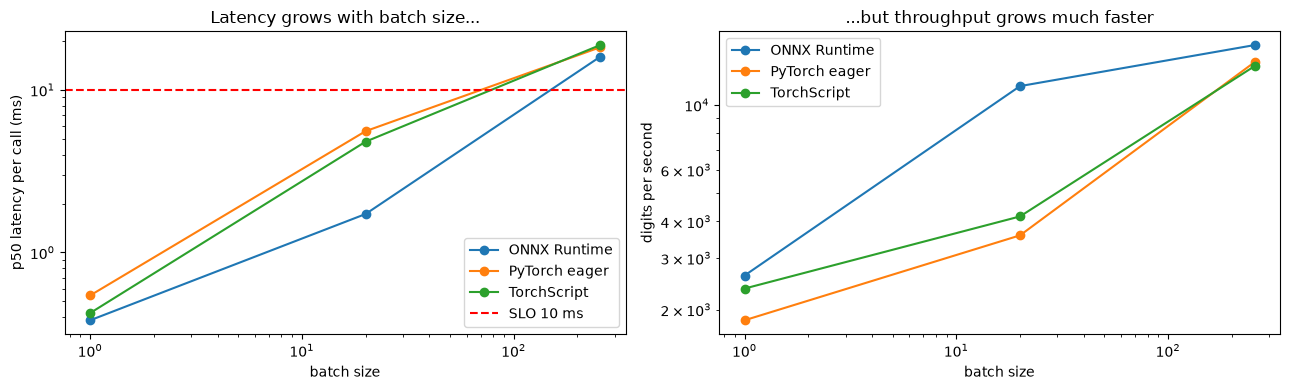

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for engine, group in bench_fp32.groupby("engine"):
    axes[0].plot(group.batch_size, group.p50_ms, marker="o", label=engine)
    axes[1].plot(group.batch_size, group.items_per_s, marker="o", label=engine)
axes[0].axhline(CFG.latency_slo_ms, color="red", ls="--", label=f"SLO {CFG.latency_slo_ms:.0f} ms")
axes[0].set(xscale="log", yscale="log", xlabel="batch size", ylabel="p50 latency per call (ms)",
            title="Latency grows with batch size...")
axes[1].set(xscale="log", yscale="log", xlabel="batch size", ylabel="digits per second",
            title="...but throughput grows much faster")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

**What the measurements show** (from this run; your absolute numbers will differ):
- For a **single digit** (batch 1) every engine needs well under a millisecond at the median. The model is so small that the fixed cost of each call dominates.
- For **one form (20 digits)** and for **big batches (256)**, **ONNX Runtime has the lowest median latency** of the three engines. Its graph optimisations and kernels are built for inference only.
- **TorchScript** is not reliably faster than eager PyTorch for a simple MLP: there is little Python overhead to remove. Its value is *portability* (the model loads without your Python class, even from C++), not speed.
- **Throughput grows with batch size**, because the per-call overhead is shared by more digits. For offline/batch jobs, batch size is the biggest performance lever.
- Look at how far **p95 and p99 are above p50**. On this busy shared machine some calls were delayed by other processes. That gap (the **tail latency**) is why SLOs are written on p95/p99 and why real benchmarks run on dedicated, idle production hardware.

---
## 9. Dynamic quantization: accuracy vs speed vs size

**Quantization** stores weights as 8-bit integers (`int8`) instead of 32-bit floats: the weights take **4x less memory**, and integer matrix multiplication is often faster on CPUs.
**Dynamic** quantization is the easiest kind: weights are converted ahead of time, and activations are quantized on the fly for every input, so **no calibration data** is needed. It works best for `Linear`/LSTM-heavy models (MLPs, Transformers, RNNs). For CNNs, *static* quantization (with a calibration set) is usually recommended; see `13_quantization_and_compression_advanced.ipynb` for the theory.

We try it in both ecosystems:
- **PyTorch**: `torch.ao.quantization.quantize_dynamic(model, {nn.Linear}, dtype=torch.qint8)`. (PyTorch is moving these APIs to the separate **`torchao`** library; the idea is identical.)
- **ONNX Runtime**: `onnxruntime.quantization.quantize_dynamic(input.onnx, output.onnx, weight_type=QuantType.QInt8)`.

Then we fill the table a release review needs: **size, accuracy, agreement with the float model, and speed**. Accuracy is measured on the full test set; agreement = how often the quantized model predicts the same class as the float model.

In [10]:
from torch.ao.quantization import quantize_dynamic as torch_quantize_dynamic
from onnxruntime.quantization import QuantType, quantize_dynamic as ort_quantize_dynamic

# --- PyTorch dynamic quantization (on a COPY: the float model must stay untouched) ---
reader_int8 = torch_quantize_dynamic(copy.deepcopy(reader), {nn.Linear}, dtype=torch.qint8).eval()
print(reader_int8.net.net)                                  # Linear layers became DynamicQuantizedLinear

# --- ONNX Runtime dynamic quantization ---
# Known quirk: the new exporter stores shape hints ("value_info") for the weights; the quantizer
# rewrites the weights and then trips over the stale hints. Removing them is safe: ORT re-infers shapes.
clean_model = onnx.load(str(ONNX_PATH))
del clean_model.graph.value_info[:]
CLEAN_PATH, ONNX_INT8_PATH = ARTIFACT_DIR / "digit_reader_clean.onnx", ARTIFACT_DIR / "digit_reader.int8.onnx"
onnx.save(clean_model, str(CLEAN_PATH))
ort_quantize_dynamic(str(CLEAN_PATH), str(ONNX_INT8_PATH), weight_type=QuantType.QInt8)
session_int8 = make_session(ONNX_INT8_PATH)
print("ONNX int8 operators:", sorted({n.op_type for n in onnx.load(str(ONNX_INT8_PATH)).graph.node}))

2026-10-21 16:41:50,904 | WARNING | Please consider to run pre-processing before quantization. Refer to example: https://github.com/microsoft/onnxruntime-inference-examples/blob/main/quantization/image_classification/cpu/ReadMe.md 


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): DynamicQuantizedLinear(in_features=64, out_features=1024, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): DynamicQuantizedLinear(in_features=1024, out_features=1024, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
  (5): ReLU()
  (6): Dropout(p=0.2, inplace=False)
  (7): DynamicQuantizedLinear(in_features=1024, out_features=10, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
)
ONNX int8 operators: ['Add', 'Cast', 'Concat', 'Div', 'DynamicQuantizeLinear', 'MatMulInteger', 'Mul', 'Relu', 'Reshape', 'Shape', 'Softmax', 'Sub']


In [11]:
def file_size_mb(obj_or_path) -> float:
    """Size on disk: either a path, or a PyTorch module saved as a state_dict into a temp file."""
    if isinstance(obj_or_path, Path):
        return obj_or_path.stat().st_size / 1e6
    tmp = ARTIFACT_DIR / "size_probe.pt"
    torch.save(obj_or_path.state_dict(), tmp)
    size = tmp.stat().st_size / 1e6
    tmp.unlink()
    return size


RUNNERS = {
    "PyTorch fp32": torch_runner(reader),
    "PyTorch int8 (dynamic)": torch_runner(reader_int8),
    "ONNX Runtime fp32": onnx_runner(session),
    "ONNX Runtime int8 (dynamic)": onnx_runner(session_int8),
}
SIZES_MB = {"PyTorch fp32": file_size_mb(reader), "PyTorch int8 (dynamic)": file_size_mb(reader_int8),
            "ONNX Runtime fp32": file_size_mb(ONNX_PATH), "ONNX Runtime int8 (dynamic)": file_size_mb(ONNX_INT8_PATH)}

reference_pred = torch_probs.argmax(1)                      # predictions of the float PyTorch model
x_form = np.ascontiguousarray(X_test[:CFG.form_size])       # one form (20 digits)
x_big = np.ascontiguousarray(np.resize(X_test, (256, 8, 8)))
form_bench = benchmark(RUNNERS, x_form).set_index("engine")
big_bench = benchmark(RUNNERS, x_big, n_iter=100).set_index("engine")

rows = []
for name, fn in RUNNERS.items():
    out = fn(X_test)
    probs = out[0] if isinstance(out, list) else out.numpy()   # ONNX returns a list of arrays
    pred = probs.argmax(1)
    rows.append({"variant": name, "size_MB": SIZES_MB[name],
                 "test_accuracy": (pred == y_test).mean(),
                 "agrees_with_fp32_%": 100 * (pred == reference_pred).mean(),
                 "max_prob_diff": np.abs(probs - torch_probs).max(),
                 "form_p50_ms": form_bench.loc[name, "p50_ms"], "form_p95_ms": form_bench.loc[name, "p95_ms"],
                 "batch256_digits_per_s": big_bench.loc[name, "items_per_s"]})
quant_table = pd.DataFrame(rows).set_index("variant")
quant_table.round({"size_MB": 2, "test_accuracy": 4, "agrees_with_fp32_%": 1, "max_prob_diff": 4,
                   "form_p50_ms": 3, "form_p95_ms": 3, "batch256_digits_per_s": 0})

,size_MB,test_accuracy,agrees_with_fp32_%,max_prob_diff,form_p50_ms,form_p95_ms,batch256_digits_per_s
variant,,,,,,,
PyTorch fp32,4.51,0.9861,100.0,0.0000,1.969,5.337,11485.0
PyTorch int8 (dynamic),1.14,0.9861,100.0,0.0319,1.070,1.484,12210.0
ONNX Runtime fp32,4.52,0.9861,100.0,0.0000,1.179,1.615,11879.0
ONNX Runtime int8 (dynamic),1.14,0.9861,100.0,0.0433,0.781,1.112,23103.0


In [12]:
base = quant_table.loc["PyTorch fp32"]
for name in ["PyTorch int8 (dynamic)", "ONNX Runtime int8 (dynamic)"]:
    row = quant_table.loc[name]
    fp32_row = quant_table.loc[name.replace("int8 (dynamic)", "fp32")]
    print(f"{name:28s}: {fp32_row.size_MB / row.size_MB:.1f}x smaller | "
          f"accuracy change {100 * (row.test_accuracy - fp32_row.test_accuracy):+.2f} points | "
          f"form latency p50 {fp32_row.form_p50_ms / row.form_p50_ms:.2f}x faster than its fp32 version")

PyTorch int8 (dynamic)      : 4.0x smaller | accuracy change +0.00 points | form latency p50 1.84x faster than its fp32 version
ONNX Runtime int8 (dynamic) : 4.0x smaller | accuracy change +0.00 points | form latency p50 1.51x faster than its fp32 version


**Reading the quantization table:**
- **Size:** int8 weights make both model files **4x smaller** (4.5 MB → 1.1 MB). That means less memory per container, smaller downloads to edge devices and faster cold starts.
- **Accuracy:** no change on the test set (98.61% for all four variants), and the int8 models predict **the same class as the float model for 100% of the test images**. The probabilities themselves move a little (max difference about 0.03-0.04). That is why we compare *predictions* and not only accuracy, and why a business threshold (here: send digits below 0.8 confidence to a human) should be re-checked on validation data after quantizing.
- **Speed:** in this run the int8 versions were faster than their fp32 versions for a 20-digit form (see the printed speed-ups) and had higher throughput at batch 256. For tiny models the gain can be small or disappear because overhead dominates; for large `Linear`-heavy models (e.g. BERT-style Transformers on CPU) 1.5-3x speed-ups are common. **Always measure on your own model and hardware.**
- **Decision:** within the 0.5-point accuracy budget and 4x smaller → we deploy the **ONNX Runtime int8** model. It also serves the C#/Java team, who can load the same `.onnx` file with ONNX Runtime's C# or Java API.
- The ORT warning about "pre-processing" refers to an optional graph-preparation step (`quant_pre_process`) that mainly helps Transformer models; we skip it for this simple MLP.

---
## 10. A small inference service with input validation and batching

The final artifact is a class the API team can wrap in FastAPI (see `12_FastAPI/03_ml_serving_with_fastapi.ipynb`) or a queue worker. It follows the patterns every serving framework (TorchServe, Triton, BentoML, Ray Serve) uses:

- **Load once** at start-up, with a **metadata file** (version, input contract, metrics) and a **checksum** so a corrupted or swapped file is detected before serving traffic.
- **Validate inputs** and fail loudly with a clear message: wrong shape, `NaN`, values outside 0..16, empty requests. A model never complains about garbage; it just returns a confident wrong answer.
- **Batching**: big requests are split into chunks of `max_batch_size` (bounded memory and latency), and many small requests are cheaper when **grouped into one call**. Servers like Triton do this automatically ("dynamic batching").
- Return **business-level output** (digit, confidence, "needs human review") plus the model version, and log the latency.

In [13]:
def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


# The metadata file that is deployed next to the model
DEPLOYED_MODEL = ONNX_INT8_PATH if quant_table.loc["ONNX Runtime int8 (dynamic)", "test_accuracy"] >= \
    quant_table.loc["ONNX Runtime fp32", "test_accuracy"] - CFG.max_accuracy_drop else ONNX_PATH
metadata = {
    "model_name": "digit_reader", "model_version": "1.0.0", "file": DEPLOYED_MODEL.name,
    "sha256": sha256(DEPLOYED_MODEL),
    "input": {"name": "pixels", "shape": ["batch", 8, 8], "dtype": "float32", "min": 0.0, "max": 16.0},
    "output": {"name": "probabilities", "classes": [str(c) for c in range(10)]},
    "review_threshold": 0.8,                    # below this confidence a human checks the digit (notebook 16)
    "test_accuracy": float(quant_table.loc["ONNX Runtime int8 (dynamic)" if DEPLOYED_MODEL == ONNX_INT8_PATH
                                           else "ONNX Runtime fp32", "test_accuracy"]),
    "exported_with": {"torch": str(torch.__version__), "onnx": onnx.__version__, "onnxruntime": ort.__version__},
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print(f"Deploying {DEPLOYED_MODEL.name}")


class DigitReaderService:
    """Production-style wrapper around an ONNX Runtime session."""

    def __init__(self, artifact_dir: Path, max_batch_size: int = CFG.max_batch_size):
        self.meta = json.loads((artifact_dir / "metadata.json").read_text())
        model_path = artifact_dir / self.meta["file"]
        if sha256(model_path) != self.meta["sha256"]:                       # integrity check
            raise RuntimeError(f"Checksum mismatch for {model_path.name}: refusing to serve")
        self.session = make_session(model_path)
        self.spec, self.max_batch_size = self.meta["input"], max_batch_size
        log.info("Loaded %s v%s", self.meta["model_name"], self.meta["model_version"])

    def _validate(self, scans) -> np.ndarray:
        x = np.asarray(scans, dtype=np.float32)                             # lists / ints are converted
        if x.ndim == 2:
            x = x[None]                                                     # single scan -> batch of one
        if x.ndim != 3 or x.shape[1:] != (8, 8):
            raise ValueError(f"expected shape [batch, 8, 8], got {list(x.shape)}")
        if len(x) == 0:
            raise ValueError("empty request")
        if not np.isfinite(x).all():
            raise ValueError("input contains NaN or infinity")
        if x.min() < self.spec["min"] or x.max() > self.spec["max"]:
            raise ValueError(f"pixel values must be in [{self.spec['min']}, {self.spec['max']}], "
                             f"got [{x.min():.1f}, {x.max():.1f}]")
        return np.ascontiguousarray(x)

    def predict(self, scans) -> list[dict]:
        start = time.perf_counter()
        x = self._validate(scans)
        probs = np.concatenate([self.session.run(None, {"pixels": x[i:i + self.max_batch_size]})[0]
                                for i in range(0, len(x), self.max_batch_size)])   # chunked batching
        classes, threshold = self.meta["output"]["classes"], self.meta["review_threshold"]
        results = [{"digit": classes[p.argmax()], "confidence": round(float(p.max()), 4),
                    "needs_review": bool(p.max() < threshold)} for p in probs]
        log.info("predicted %d digits in %.2f ms (model v%s)", len(x),
                 (time.perf_counter() - start) * 1000, self.meta["model_version"])
        return results


service = DigitReaderService(ARTIFACT_DIR)
form_result = service.predict(X_test[:CFG.form_size])
print("First 5 digits of the form:", form_result[:5])
print("True labels              :", y_test[:5].tolist())
print("Digits flagged for review:", sum(r["needs_review"] for r in form_result), "of", len(form_result))

2026-10-21 16:42:03,403 | INFO | Loaded digit_reader v1.0.0


2026-10-21 16:42:03,405 | INFO | predicted 20 digits in 1.13 ms (model v1.0.0)


Deploying digit_reader.int8.onnx
First 5 digits of the form: [{'digit': '5', 'confidence': 1.0, 'needs_review': False}, {'digit': '2', 'confidence': 1.0, 'needs_review': False}, {'digit': '8', 'confidence': 0.9982, 'needs_review': False}, {'digit': '1', 'confidence': 0.508, 'needs_review': True}, {'digit': '7', 'confidence': 1.0, 'needs_review': False}]
True labels              : [5, 2, 8, 1, 7]
Digits flagged for review: 1 of 20


In [14]:
# Bad requests must be rejected with a clear reason, not answered
bad_requests = {
    "wrong shape (28x28 image)": np.zeros((1, 28, 28)),
    "0..255 pixels instead of 0..16": np.full((2, 8, 8), 255.0),
    "missing pixel (NaN)": np.where(np.eye(8, dtype=bool), np.nan, 1.0)[None],
    "empty batch": np.zeros((0, 8, 8)),
}
for description, request in bad_requests.items():
    try:
        service.predict(request)
        print(f"NOT REJECTED: {description}")
    except ValueError as err:
        print(f"rejected {description:32s} -> {err}")

rejected wrong shape (28x28 image)        -> expected shape [batch, 8, 8], got [1, 28, 28]
rejected 0..255 pixels instead of 0..16   -> pixel values must be in [0.0, 16.0], got [255.0, 255.0]
rejected missing pixel (NaN)              -> input contains NaN or infinity
rejected empty batch                      -> empty request


In [15]:
# Batching: 360 digits sent one request at a time vs grouped into one request
log.setLevel(logging.WARNING)                               # silence per-request logs for this timing

start = time.perf_counter()
one_by_one = [service.predict(X_test[i])[0] for i in range(len(X_test))]
t_single = time.perf_counter() - start

start = time.perf_counter()
grouped = service.predict(X_test)                           # one call, chunked internally
t_grouped = time.perf_counter() - start

log.setLevel(logging.INFO)
assert [r["digit"] for r in one_by_one] == [r["digit"] for r in grouped]   # same answers either way
print(f"one request per digit : {t_single * 1000:7.1f} ms for {len(X_test)} digits")
print(f"one grouped request   : {t_grouped * 1000:7.1f} ms  ({t_single / t_grouped:.0f}x faster)")

one request per digit :    81.1 ms for 360 digits
one grouped request   :    18.4 ms  (4x faster)


Grouping is several times faster (between 4x and 14x across our runs on a busy shared machine), because each call has a fixed overhead (Python, input checks, ORT dispatch) that is now paid once instead of 360 times. This is why batch-scoring jobs always send big batches, and why online servers implement *dynamic batching*: they wait a few milliseconds to collect concurrent requests into one model call.

---
## 11. Automated release tests

Before a model artifact is promoted to production, CI runs tests like these (normally with `pytest`; see `15_MLOps/07_testing_in_ml/`). Any failure blocks the release.

In [16]:
def test_onnx_matches_pytorch():
    out = make_session(ONNX_PATH).run(None, {"pixels": X_test})[0]
    np.testing.assert_allclose(out, torch_probs, rtol=1e-4, atol=1e-5)


def test_dynamic_batch_sizes():
    for n in [1, 3, 64, 300]:
        assert service.session.run(None, {"pixels": X_test[:n]})[0].shape == (n, 10)


def test_quantization_within_accuracy_budget():
    drop = quant_table.loc["ONNX Runtime fp32", "test_accuracy"] - quant_table.loc["ONNX Runtime int8 (dynamic)", "test_accuracy"]
    assert drop <= CFG.max_accuracy_drop, f"int8 loses {drop:.4f} accuracy"


def test_latency_slo_for_one_form():
    """End-to-end service latency (validation + model + post-processing) for one 20-digit form.
    Shared CI machines are noisy, so we measure 3 times and keep the best p95. Real SLO sign-off
    happens with a load test on the production hardware."""
    log.setLevel(logging.WARNING)                                    # no per-request logs while timing
    p95 = min(benchmark({"service": service.predict}, x_form)["p95_ms"].iloc[0] for _ in range(3))
    log.setLevel(logging.INFO)
    print(f"  service p95 for one form: {p95:.2f} ms (SLO {CFG.latency_slo_ms} ms)")
    assert p95 < CFG.latency_slo_ms, f"p95 {p95:.2f} ms breaks the {CFG.latency_slo_ms} ms SLO"


def test_service_rejects_bad_input():
    for request in bad_requests.values():
        try:
            service.predict(request)
        except ValueError:
            continue
        raise AssertionError("bad request was accepted")


def test_probabilities_are_valid():
    probs = service.session.run(None, {"pixels": X_test[:50]})[0]
    assert np.all(probs >= 0) and np.allclose(probs.sum(1), 1, atol=1e-4)


for test in [test_onnx_matches_pytorch, test_dynamic_batch_sizes, test_quantization_within_accuracy_budget,
             test_latency_slo_for_one_form, test_service_rejects_bad_input, test_probabilities_are_valid]:
    test()
    print(f"PASSED  {test.__name__}")

print("\nRelease artifacts:")
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"  {f.name:34s} {f.stat().st_size / 1e6:6.2f} MB")

PASSED  test_onnx_matches_pytorch
PASSED  test_dynamic_batch_sizes
PASSED  test_quantization_within_accuracy_budget


  service p95 for one form: 1.26 ms (SLO 10.0 ms)
PASSED  test_latency_slo_for_one_form
PASSED  test_service_rejects_bad_input
PASSED  test_probabilities_are_valid

Release artifacts:
  digit_reader.int8.onnx               1.14 MB
  digit_reader.onnx                    4.52 MB
  digit_reader.pt2                     4.54 MB
  digit_reader.torchscript.pt          4.53 MB
  digit_reader_clean.onnx              4.52 MB
  metadata.json                        0.00 MB


---
## 12. Production checklist, summary and resources

### Model release checklist
| # | Check | Where in this notebook |
|---|---|---|
| 1 | `model.eval()` and `torch.inference_mode()` in every inference path | Section 3 |
| 2 | Preprocessing (normalisation) and postprocessing (softmax) **inside** the exported model | Section 4 |
| 3 | Export with a **dynamic batch** dimension and named inputs/outputs | Sections 5-6 |
| 4 | `onnx.checker` passes; graph inspected (no training-only ops like dropout) | Section 6 |
| 5 | **Numerical parity** vs PyTorch with explicit tolerances + identical predicted classes | Section 7 |
| 6 | Benchmarked with warm-up, p50/p95/p99, fixed threads, on the **target hardware** | Section 8 |
| 7 | Quantization judged on **size, accuracy, agreement and latency**, within an agreed budget | Section 9 |
| 8 | Metadata (version, input contract, metrics, library versions) and **checksum** shipped with the model | Section 10 |
| 9 | Service validates inputs, batches requests, logs latency and model version | Section 10 |
| 10 | Automated release tests in CI; monitoring of latency, errors and input drift after release | Section 11, `15_MLOps/06_monitoring/` |

### Summary
| Practice | What we did | Where it is used in industry |
|---|---|---|
| eval + inference_mode | deterministic, cheaper inference | every PyTorch service |
| Self-contained model | normalisation + softmax baked into the graph | avoids training/serving skew |
| TorchScript / torch.export | Python-free model files | LibTorch C++ services, ExecuTorch mobile |
| ONNX + ONNX Runtime | one file for Python, C#, Java, C++, JS | Windows/Azure, edge devices, cross-team handover |
| Parity tests | `assert_allclose` + same predicted class | CI gate for every export |
| Proper benchmarks | warm-up, percentiles, batch-size sweep | capacity planning, SLOs |
| Dynamic int8 quantization | 4x smaller weights, measured speed and accuracy | CPU serving of Transformers, recommenders |
| Inference service | checksum, validation, chunked batching, logging | FastAPI / Triton / TorchServe / BentoML wrappers |

### Practice exercises
1. Set `num_threads` to 4 in `ServeConfig` and re-run Section 8. Which batch sizes benefit from more threads, and which do not? Why?
2. Export the CNN from notebook 16 to ONNX. Does ONNX Runtime **dynamic** quantization help a convolution-heavy model? Then read about *static* quantization with a calibration set (`onnxruntime.quantization.quantize_static`).
3. Remove `dynamic_shapes` from the ONNX export and call the session with 7 digits. Read the error message: this is a very common production bug.
4. Try `torch.compile(reader)` and benchmark it against eager mode (first call is slow: compilation!).
5. Wrap `DigitReaderService` in a FastAPI endpoint with a Pydantic request model (`12_FastAPI/03_ml_serving_with_fastapi.ipynb`).

### Resources (checked)
- PyTorch tutorial, *Export a PyTorch model to ONNX* (new `dynamo=True` exporter, parity with ONNX Runtime): https://docs.pytorch.org/tutorials/beginner/onnx/export_simple_model_to_onnx_tutorial.html
- PyTorch `torch.onnx` export docs: https://docs.pytorch.org/docs/stable/onnx_export.html
- PyTorch `torch.export` docs: https://docs.pytorch.org/docs/stable/export.html
- PyTorch tutorial, *Saving and Loading Models*: https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
- ONNX Runtime Python API: https://onnxruntime.ai/docs/api/python/api_summary.html
- ONNX Runtime, *Quantize ONNX models* (dynamic vs static, when to use which): https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html
- ONNX Runtime, graph optimizations: https://onnxruntime.ai/docs/performance/model-optimizations/graph-optimizations.html
- `torchao`, PyTorch's new quantization library: https://github.com/pytorch/ao
- NVIDIA Triton Inference Server, dynamic batching: https://docs.nvidia.com/deeplearning/triton-inference-server/user-guide/docs/user_guide/batcher.html
- Made With ML (Goku Mohandas), serving and testing ML systems: https://madewithml.com/

### Related notebooks in this repo
- Training the model professionally: [`16_industry_pytorch_training_pipeline.ipynb`](16_industry_pytorch_training_pipeline.ipynb)
- Compression theory (quantization, pruning, distillation): [`08_model_compression.ipynb`](08_model_compression.ipynb), [`13_quantization_and_compression_advanced.ipynb`](13_quantization_and_compression_advanced.ipynb)
- Serving with an API: [`../12_FastAPI/03_ml_serving_with_fastapi.ipynb`](../12_FastAPI/03_ml_serving_with_fastapi.ipynb)
- Advanced model serving: [`../15_MLOps/11_model_serving_advanced.ipynb`](../15_MLOps/11_model_serving_advanced.ipynb)
- Edge deployment: [`../16_Deployment/04_edge_deployment.ipynb`](../16_Deployment/04_edge_deployment.ipynb)
- Monitoring after release: [`../15_MLOps/06_monitoring/`](../15_MLOps/06_monitoring/)